In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [3]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

data = pd.read_csv(url, names=columns)

print("Dataset loaded successfully!")
print("Shape:", data.shape)

data.head()

Dataset loaded successfully!
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
print("Column Names:")
print(data.columns.tolist())

print("\nDataset Shape:")
print(data.shape)

print("\nMissing Values:")
print(data.isnull().sum())

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset Shape:
(768, 9)

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [5]:
# Replace invalid zero values with NaN
columns_to_replace = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in columns_to_replace:
    data[col] = data[col].replace(0, np.nan)

# Replace missing values with median
for col in columns_to_replace:
    data[col] = data[col].fillna(data[col].median())

print("Preprocessing completed.")

data.head()

Preprocessing completed.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [6]:
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Outcome")

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target:
Outcome

X shape: (768, 8)
y shape: (768,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (614, 8)
Testing data : (154, 8)


In [8]:
model_no_scaling = LogisticRegression(max_iter=1000)

model_no_scaling.fit(X_train, y_train)

y_pred_no_scaling = model_no_scaling.predict(X_test)

print("Model trained without feature scaling.")

Model trained without feature scaling.


In [9]:
accuracy_no = accuracy_score(y_test, y_pred_no_scaling)
precision_no = precision_score(y_test, y_pred_no_scaling)
recall_no = recall_score(y_test, y_pred_no_scaling)
f1_no = f1_score(y_test, y_pred_no_scaling)

print("WITHOUT FEATURE SCALING")
print("-----------------------")
print("Accuracy :", accuracy_no)
print("Precision:", precision_no)
print("Recall   :", recall_no)
print("F1-Score :", f1_no)

WITHOUT FEATURE SCALING
-----------------------
Accuracy : 0.7012987012987013
Precision: 0.5869565217391305
Recall   : 0.5
F1-Score : 0.54


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [11]:
model_scaling = LogisticRegression(max_iter=1000)

model_scaling.fit(X_train_scaled, y_train)

y_pred_scaling = model_scaling.predict(X_test_scaled)

print("Model trained with feature scaling.")

Model trained with feature scaling.


In [12]:
accuracy_scaled = accuracy_score(y_test, y_pred_scaling)
precision_scaled = precision_score(y_test, y_pred_scaling)
recall_scaled = recall_score(y_test, y_pred_scaling)
f1_scaled = f1_score(y_test, y_pred_scaling)

print("WITH FEATURE SCALING")
print("--------------------")
print("Accuracy :", accuracy_scaled)
print("Precision:", precision_scaled)
print("Recall   :", recall_scaled)
print("F1-Score :", f1_scaled)

WITH FEATURE SCALING
--------------------
Accuracy : 0.7077922077922078
Precision: 0.6
Recall   : 0.5
F1-Score : 0.5454545454545454


In [13]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Without Scaling": [
        accuracy_no,
        precision_no,
        recall_no,
        f1_no
    ],
    "With Scaling": [
        accuracy_scaled,
        precision_scaled,
        recall_scaled,
        f1_scaled
    ]
})

comparison

,Metric,Without Scaling,With Scaling
0,Accuracy,0.701299,0.707792
1,Precision,0.586957,0.600000
2,Recall,0.500000,0.500000
3,F1-Score,0.540000,0.545455


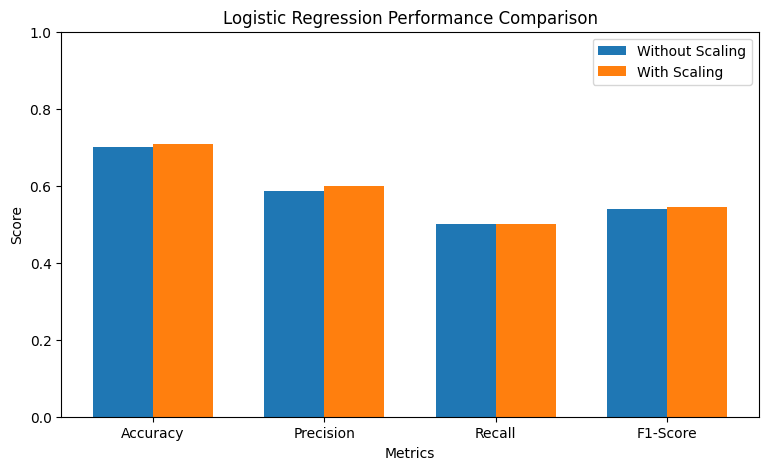

In [14]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

without_scaling = [
    accuracy_no,
    precision_no,
    recall_no,
    f1_no
]

with_scaling = [
    accuracy_scaled,
    precision_scaled,
    recall_scaled,
    f1_scaled
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, without_scaling, width, label="Without Scaling")
plt.bar(x + width/2, with_scaling, width, label="With Scaling")

plt.xlabel("Metrics")
plt.ylabel("Score")
plt.title("Logistic Regression Performance Comparison")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()

plt.show()